In [ ]:
# libs
from google.colab import drive, files
from zipfile import ZipFile
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:
# data loading
TRAINSET_PATH = "/content/drive/MyDrive/Plant_Disease_Dataset/trainset.zip"
TESTSET_PATH = "/content/drive/MyDrive/Plant_Disease_Dataset/testset.zip"

DIR_PATH = "/content/Dataset"

drive.mount("/content/drive")

with ZipFile(TRAINSET_PATH, "r") as zip:
  zip.extractall(DIR_PATH)

with ZipFile(TESTSET_PATH, "r") as zip:
  zip.extractall(DIR_PATH)

print("Data is ready to train and test resNet")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data is ready to train and test resNet


In [ ]:
# data setup
TRAIN_DATA = "/content/Dataset/TRAINSET"
TEST_DATA = "/content/Dataset/TESTSET"

train_dataset = tf.keras.utils.image_dataset_from_directory(
    directory = TRAIN_DATA,
    image_size = (224, 224),
    subset = "training",
    validation_split = 0.2,
    seed = 42,
    batch_size = 32,
    label_mode = "int"
)

valid_dataset = tf.keras.utils.image_dataset_from_directory(
    directory = TRAIN_DATA,
    image_size = (224, 224),
    subset = "validation",
    validation_split = 0.2,
    seed = 42,
    batch_size = 32,
    label_mode = "int"
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    directory = TEST_DATA,
    image_size = (224, 224),
    batch_size = 32,
    shuffle = False,
    label_mode = "int"

)

print("Training + validation + testing set is ready to go:")

Found 17888 files belonging to 12 classes.
Using 14311 files for training.
Found 17888 files belonging to 12 classes.
Using 3577 files for validation.
Found 422 files belonging to 12 classes.
Training + validation + testing set is ready to go:


In [ ]:
# parameters
num_classes = len(train_dataset.class_names)
print("Classes:", train_dataset.class_names)
print("Number of classes:", num_classes)

INPUT_SIZE = (224, 224, 3)
BATCH_SIZE = 32
LEARNING_RATE = 0.0001
EPOCHS = 30
WEIGHTS_DEC = 1e-4

Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Number of classes: 12


In [ ]:
# Bottleneck Residual Block
def bottleneck_block(x, filters, stride=1, projection=False):

    shortcut = x

    # 1x1 convolution: Reduce channels
    x = layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # 3x3 convolution: Extract features
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # 1x1 convolution: Expand channels
    x = layers.Conv2D(filters * 4, 1, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)

    # Match shortcut dimensions if needed
    if projection:
        shortcut = layers.Conv2D(filters * 4, 1, strides=stride, padding="same",use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    # Add shortcut connection
    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)

    return x


# Residual Stage
def resnet_stage(x, filters, blocks, stride):

    # First block changes dimensions
    x = bottleneck_block(x, filters, stride=stride, projection=True)

    # Remaining blocks keep dimensions
    for _ in range(1, blocks):
        x = bottleneck_block(x, filters, stride=1, projection=False)

    return x


# Build ResNet-50
def build_resnet50(input_shape=(224, 224, 3), num_classes=num_classes):

    inputs = layers.Input(shape=input_shape)

    # data aug
    data_aug  = tf.keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ])

    x = data_aug(inputs)

    # Initial convolution
    x = layers.Conv2D(64, 7, strides=2, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Max pooling
    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

    # Stage 1: 3 blocks
    x = resnet_stage(x, 64, 3, stride=1)

    # Stage 2: 4 blocks
    x = resnet_stage(x, 128, 4, stride=2)

    # Stage 3: 6 blocks
    x = resnet_stage(x, 256, 6, stride=2)

    # Stage 4: 3 blocks
    x = resnet_stage(x, 512, 3, stride=2)

    # Convert feature maps into vector
    x = layers.GlobalAveragePooling2D()(x)

    # Final classification layer
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return Model(inputs, outputs, name="Custom_ResNet50")


# Create Model
model = build_resnet50(input_shape=INPUT_SIZE, num_classes=num_classes)

#summary
model.summary()

# compiling
model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=LEARNING_RATE, weight_decay=WEIGHTS_DEC),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Model: "Custom_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_53 (Conv2D)  │ (None, 112, 112,  │      9,408 │ sequential_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_53[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_49 (ReLU)     │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ re_lu_49[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_54 (Conv2D)  │ (None, 56, 56,    │      4,096 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_54[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_50 (ReLU)     │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_55 (Conv2D)  │ (None, 56, 56,    │     36,864 │ re_lu_50[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_55[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_51 (ReLU)     │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_56 (Conv2D)  │ (None, 56, 56,    │     16,384 │ re_lu_51[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_57 (Conv2D)  │ (None, 56, 56,    │     16,384 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │      1,024 │ conv2d_56[0][0]   │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │      1,024 │ conv2d_57[0][0]   │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_16 (Add)        │ (None, 56, 56,    │          0 │ batch_normalizat

 Total params: 23,585,740 (89.97 MB)

 Trainable params: 23,532,620 (89.77 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [ ]:
# training
cb = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
      tf.keras.callbacks.ModelCheckpoint(filepath='best.keras', monitor='val_accuracy', save_best_only=True),
      tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)]

model.fit(
    train_dataset,
    epochs=EPOCHS,
    validation_data=valid_dataset,
    callbacks=cb
)

Epoch 1/30
448/448 ━━━━━━━━━━━━━━━━━━━━ 292s 585ms/step - accuracy: 0.5986 - loss: 1.1823 - val_accuracy: 0.3226 - val_loss: 3.0707 - learning_rate: 1.0000e-04
Epoch 2/30
448/448 ━━━━━━━━━━━━━━━━━━━━ 276s 617ms/step - accuracy: 0.7587 - loss: 0.7080 - val_accuracy: 0.4610 - val_loss: 2.3969 - learning_rate: 1.0000e-04
Epoch 3/30
448/448 ━━━━━━━━━━━━━━━━━━━━ 275s 614ms/step - accuracy: 0.8217 - loss: 0.5199 - val_accuracy: 0.5893 - val_loss: 2.3428 - learning_rate: 1.0000e-04
Epoch 4/30
448/448 ━━━━━━━━━━━━━━━━━━━━ 274s 612ms/step - accuracy: 0.8519 - loss: 0.4326 - val_accuracy: 0.5404 - val_loss: 2.7393 - learning_rate: 1.0000e-04
Epoch 5/30
448/448 ━━━━━━━━━━━━━━━━━━━━ 273s 609ms/step - accuracy: 0.8702 - loss: 0.3684 - val_accuracy: 0.4716 - val_loss: 3.4597 - learning_rate: 1.0000e-04
Epoch 6/30
448/448 ━━━━━━━━━━━━━━━━━━━━ 284s 635ms/step - accuracy: 0.9199 - loss: 0.2334 - val_accuracy: 0.6039 - val_loss: 1.7010 - learning_rate: 5.0000e-05
Epoch 7/30
448/448 ━━━━━━━━━━━━━━━━━━━━ 

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.9028 - loss: 0.3186
Loss: 0.3185647428035736
Accuracy: 90.0%
12
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step


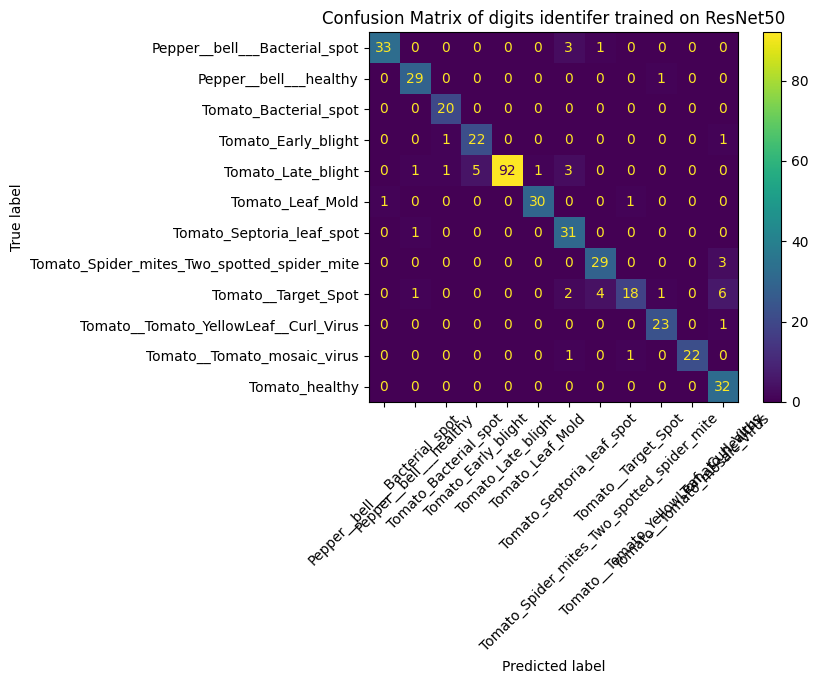

In [ ]:
# libs
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# metrics & evaluation
loss, accuracy = model.evaluate(test_dataset, verbose=1)
print(f"Loss: {loss}")
print(f"Accuracy: {round(accuracy * 100, 0)}%")

y_pred = model.predict(test_dataset)
y_pred = np.argmax(y_pred, axis=1)
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

cm = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=test_dataset.class_names)
display.plot()
plt.title("Confusion Matrix of digits identifer trained on ResNet50")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# downloading for streamlit app
model.save("ResNet.keras")
files.download("ResNet.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>